# Lab 11: Word Embeddings & Transformer Self-Attention

**Name:** Soren Patel

**Alpha:** 284932

In this lab, you will test the **Four Core Pillars** of word embeddings and build/inspect **Transformer Self-Attention** in PyTorch.

In [1]:
import time
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel

torch.manual_seed(42)
print("PyTorch Version:", torch.__version__)

PyTorch Version: 2.14.1+cpu


## Part 1: Math vs. Hardware — Benchmarking Token Lookup (25 pts)

Mathematically, looking up token indices $\mathbf{I} \in \{0, \dots, V-1\}^{B \times W}$ in an embedding matrix $\mathbf{E} \in \mathbb{R}^{V \times D}$ is equivalent to multiplying one-hot vectors by $\mathbf{E}$. In hardware, `nn.Embedding` performs a direct $O(1)$ pointer gather.

**TODO 1.1:** Complete both functions below and verify they produce identical outputs.

In [2]:
def math_onehot_lookup(token_ids: torch.Tensor, E_weight: torch.Tensor) -> torch.Tensor:
    """
    Naive Math View: Convert integer token_ids (B, W) into float32 one-hot vectors (B, W, V)
    and multiply by the embedding matrix E_weight (V, D).
    """
    V = E_weight.shape[0]
    onehot = F.one_hot(token_ids,num_classes = V).float()
    return onehot @ E_weight

def systems_pointer_lookup(token_ids: torch.Tensor, embedding_layer: nn.Embedding) -> torch.Tensor:
    """
    Systems View: Use the nn.Embedding layer directly to gather rows in O(1) time.
    """
    return embedding_layer(token_ids)

# --- Benchmark & Verification ---
V, D = 50_000, 512
B, W = 8, 128  # 8 sequences of length 128

embedding_layer = nn.Embedding(num_embeddings=V, embedding_dim=D)
token_ids = torch.randint(0, V, (B, W))

# Time the Naive One-Hot GEMM
t0 = time.perf_counter()
out_math = math_onehot_lookup(token_ids, embedding_layer.weight)
t_math = (time.perf_counter() - t0) * 1000

# Time the Systems Pointer Lookup
t0 = time.perf_counter()
out_sys = systems_pointer_lookup(token_ids, embedding_layer)
t_sys = (time.perf_counter() - t0) * 1000

assert torch.allclose(out_math, out_sys, atol=1e-5), "Outputs do not match!"
onehot_megabytes = (B * W * V * 4) / (1024 ** 2)

print(f"Outputs match! Shape: {out_sys.shape}")
print(f"One-Hot Intermediate Tensor Size: {onehot_megabytes:.1f} MB of 99.998% zeros!")
print(f"Naive One-Hot GEMM Time: {t_math:.2f} ms")
print(f"Systems Pointer Gather Time: {t_sys:.3f} ms")
print(f"Hardware Speedup: {t_math / t_sys:.1f}x faster!")

Outputs match! Shape: torch.Size([8, 128, 512])
One-Hot Intermediate Tensor Size: 195.3 MB of 99.998% zeros!
Naive One-Hot GEMM Time: 317.12 ms
Systems Pointer Gather Time: 12.609 ms
Hardware Speedup: 25.2x faster!


**Question 1.1:** Why did `math_onehot_lookup` take so much longer and allocate over 200 MB of extra RAM for just 8 short paragraphs, even though it computed the exact same answer as `systems_pointer_lookup`?

**Your Answer:** With onehot, we have to build a large tensor (exactly 195.3MB) where most of it is 0's anyway. It then has to calculate this matrix multiplication against E, taking a much larger computing time. Instead, systems pointer lookup reads from the memory addresses in constant time.

## Part 2: Navigating the Geometry of $\mathbb{R}^D$ (25 pts)

Let's load the real pre-trained token embedding table $\mathbf{E} \in \mathbb{R}^{30522 \times 768}$ from `distilbert-base-uncased` and explore its geometry using Cosine Similarity.

In [3]:
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
model = AutoModel.from_pretrained("distilbert-base-uncased", output_attentions=True, output_hidden_states=True)
model.eval()

# Extract the static embedding lookup matrix E of shape (V, D) = (30522, 768)
E_matrix = model.embeddings.word_embeddings.weight.detach()
# Pre-normalize rows of E so cosine similarity is just a fast dot product!
E_norm = F.normalize(E_matrix, p=2, dim=1)
print("Loaded static embedding matrix E of shape:", E_matrix.shape)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded static embedding matrix E of shape: torch.Size([30522, 768])


In [4]:
def find_nearest_tokens(word: str, top_k: int = 6):
    """
    Given a single-token word, compute cosine similarity between its normalized vector
    and all rows in E_norm, returning the top_k closest words and their scores.
    """
    token_id = tokenizer.convert_tokens_to_ids(word.lower())
    assert token_id != tokenizer.unk_token_id, f"'{word}' is not a single token in the vocabulary!"

    vect = E_norm[token_id]
    similarities = E_norm @ vect
    vals, inds = torch.topk(similarities, k = top_k)
    words = tokenizer.convert_ids_to_tokens(inds.tolist())
    return [(w, round(v.item(),3)) for w,v in zip(words,vals)]

for query_word in ["destroyer", "submarine", "cyber", "annapolis"]:
    print(f"\nTop neighbors for '{query_word}':", find_nearest_tokens(query_word, top_k=6))


Top neighbors for 'destroyer': [('destroyer', 1.0), ('destroyers', 0.829), ('frigate', 0.707), ('warship', 0.705), ('battleship', 0.704), ('warships', 0.698)]

Top neighbors for 'submarine': [('submarine', 1.0), ('submarines', 0.817), ('frigate', 0.653), ('battleship', 0.645), ('warship', 0.644), ('torpedoes', 0.642)]

Top neighbors for 'cyber': [('cyber', 1.0), ('hacker', 0.658), ('techno', 0.651), ('23rd', 0.65), ('digitally', 0.647), ('22nd', 0.647)]

Top neighbors for 'annapolis': [('annapolis', 1.0), ('1764', 0.766), ('1732', 0.761), ('1713', 0.76), ('1761', 0.758), ('1711', 0.757)]


In [5]:
def solve_analogy(word_a: str, word_b: str, word_c: str, top_k: int = 4):
    """
    Solves: word_a is to word_b as word_c is to ???
    Computes target_vec = E_norm[b] - E_norm[a] + E_norm[c], normalizes it,
    and returns the top_k closest words in E_norm.
    """
    id_a = tokenizer.convert_tokens_to_ids(word_a.lower())
    id_b = tokenizer.convert_tokens_to_ids(word_b.lower())
    id_c = tokenizer.convert_tokens_to_ids(word_c.lower())

    target = E_norm[id_b]-E_norm[id_a]+E_norm[id_c]
    target = F.normalize(target,p=2,dim=0)
    similarities = E_norm @ target
    similarities[[id_a,id_b,id_c]] = -float("inf")

    vals,inds = torch.topk(similarities, k=top_k)
    words = tokenizer.convert_ids_to_tokens(inds.tolist())
    return [(w,round(v.item(),3)) for w,v in zip(words,vals)]

print("man : king :: woman ->", solve_analogy("man", "king", "woman"))
print("paris : france :: tokyo ->", solve_analogy("paris", "france", "tokyo"))
print("army : general :: navy ->", solve_analogy("army", "general", "navy"))

man : king :: woman -> [('queen', 0.646), ('princess', 0.513), ('kings', 0.498), ('monarch', 0.492)]
paris : france :: tokyo -> [('japan', 0.592), ('italy', 0.574), ('chiba', 0.565), ('asahi', 0.564)]
army : general :: navy -> [('admiral', 0.428), ('generals', 0.428), ('commodore', 0.384), ('seamen', 0.366)]


## Part 3: Coding Scaled Dot-Product Self-Attention from Scratch (25 pts)

Implement the core Transformer equation:
$$\text{Attention}(\mathbf{Q}, \mathbf{K}, \mathbf{V}) = \text{Softmax}\!\left(\frac{\mathbf{Q}\mathbf{K}^\top}{\sqrt{d_k}}\right)\mathbf{V}$$

In [6]:
def scaled_dot_product_attention(Q: torch.Tensor, K: torch.Tensor, V: torch.Tensor):
    """
    Args:
        Q, K, V: Tensors of shape (W, d_k)
    Returns:
        H: Contextualized output vectors of shape (W, d_k)
        A: Attention weight matrix of shape (W, W) where each row sums to 1.0
    """
    d_k = Q.shape[-1]
    temp = (Q@K.T) / math.sqrt(d_k)
    A = torch.softmax(temp, dim=1)
    H = A@V
    return H, A

# --- Synthetic "Semantic Tugboat" Test on ["foggy", "naval", "port"] ---
# Suppose d_k = 4, and we have 3 tokens: 0="foggy", 1="naval", 2="port"
Q_toy = torch.tensor([
    [1.0, 0.0, 0.0, 0.0],  # foggy query
    [0.0, 1.0, 0.0, 0.0],  # naval query
    [0.0, 2.5, 1.0, 0.0],  # port query (strongly looking for maritime adjectives in dim 1!)
])
K_toy = torch.tensor([
    [1.0, 0.0, 0.0, 0.0],  # foggy key
    [0.0, 2.5, 0.0, 0.0],  # naval key (advertises maritime adjective in dim 1!)
    [0.0, 0.0, 1.0, 0.0],  # port key
])
V_toy = torch.tensor([
    [1.0, 0.0, 0.0, 0.0],  # foggy value
    [0.0, 1.0, 0.0, 0.0],  # naval value (pure maritime feature)
    [0.0, 0.0, 1.0, 0.0],  # port value (initially orthogonal to naval!)
])

H_toy, A_toy = scaled_dot_product_attention(Q_toy, K_toy, V_toy)
print("Attention Weights A (rows = [foggy, naval, port]):\n", A_toy.round(decimals=3))
print("\nCosine similarity between 'port' and 'naval' BEFORE Attention:",
      F.cosine_similarity(V_toy[2], V_toy[1], dim=0).item())
print("Cosine similarity between 'port' and 'naval' AFTER Attention:",
      F.cosine_similarity(H_toy[2], V_toy[1], dim=0).item())

Attention Weights A (rows = [foggy, naval, port]):
 tensor([[0.4520, 0.2740, 0.2740],
        [0.1820, 0.6360, 0.1820],
        [0.0390, 0.8960, 0.0650]])

Cosine similarity between 'port' and 'naval' BEFORE Attention: 0.0
Cosine similarity between 'port' and 'naval' AFTER Attention: 0.9964302182197571


## Part 4: Watching `"port"` Change Meaning in a Real Transformer (25 pts)

Now let's pass two very different sentences containing `"port"` through `DistilBERT` and measure how Self-Attention pulls their vectors apart across the 6 Transformer layers!

Layer 0 Cosine Similarity between naval 'port' and network 'port': 1.0000
Layer 1 Cosine Similarity between naval 'port' and network 'port': 0.7129
Layer 2 Cosine Similarity between naval 'port' and network 'port': 0.7205
Layer 3 Cosine Similarity between naval 'port' and network 'port': 0.7405
Layer 4 Cosine Similarity between naval 'port' and network 'port': 0.8007
Layer 5 Cosine Similarity between naval 'port' and network 'port': 0.7946
Layer 6 Cosine Similarity between naval 'port' and network 'port': 0.5950


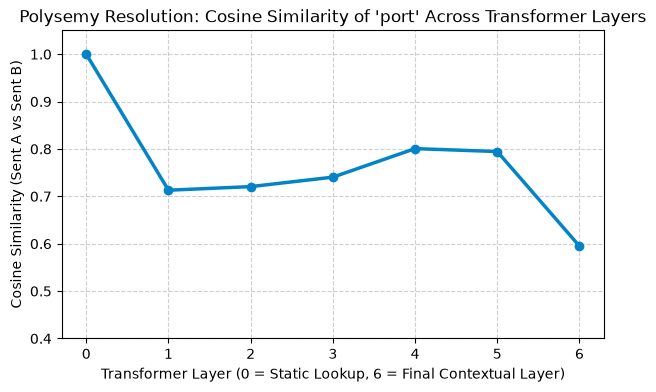

In [7]:
sent_a = "The destroyer anchored in the foggy naval port."
sent_b = "Plug the ethernet cable into the open network port."

inputs_a = tokenizer(sent_a, return_tensors="pt")
inputs_b = tokenizer(sent_b, return_tensors="pt")

tokens_a = tokenizer.convert_ids_to_tokens(inputs_a["input_ids"][0])
tokens_b = tokenizer.convert_ids_to_tokens(inputs_b["input_ids"][0])

idx_port_a = tokens_a.index("port")
idx_port_b = tokens_b.index("port")

with torch.no_grad():
    out_a = model(**inputs_a)
    out_b = model(**inputs_b)

# out.hidden_states is a tuple of 7 tensors: Layer 0 (static embedding) through Layer 6 (final layer)
# Each tensor has shape (1, W, 768)
# TODO: Compute the cosine similarity between the vector for "port" in Sentence A and Sentence B
# at EVERY layer from Layer 0 to Layer 6, and store them in a list `layer_similarities`.
layer_similarities = []
for layer_idx in range(len(out_a.hidden_states)):
    vec_a = out_a.hidden_states[layer_idx][0,idx_port_a]
    vec_b = out_b.hidden_states[layer_idx][0,idx_port_b]
    similarity = F.cosine_similarity(vec_a,vec_b, dim=0).item()
    layer_similarities.append(similarity)

for l, sim in enumerate(layer_similarities):
    print(f"Layer {l} Cosine Similarity between naval 'port' and network 'port': {sim:.4f}")

# Plot the divergence across layers
plt.figure(figsize=(7, 4))
plt.plot(range(len(layer_similarities)), layer_similarities, marker="o", linewidth=2.5, color="#0284c7")
plt.title("Polysemy Resolution: Cosine Similarity of 'port' Across Transformer Layers")
plt.xlabel("Transformer Layer (0 = Static Lookup, 6 = Final Contextual Layer)")
plt.ylabel("Cosine Similarity (Sent A vs Sent B)")
plt.ylim(0.4, 1.05)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

**Question 4.1:** Why is the cosine similarity between `"port"` in Sentence A and `"port"` in Sentence B nearly `1.0` at Layer 0, and why does it drop steadily as we go deeper into Layer 6?

**Your Answer:** *Write 2-3 sentences here.*: The cosine similarity is ~1.0 at layer 0 since when the word vectors come from the embedding, they are not taking the context (surrounding words in the sentence) into consideration. They are just the same vector for the word "port." As we go deeper into layer 6, the cosine similiarity drops steadily due to self attention. The context words are taken into consideration, so like a tugboat, the words "destroyer" and "naval" pull port in a different direction than the words "ethernet," "cable," and "network."

## 5. Additional Items and Exploration

Below are two plots, showing how much "attention" that port gets from every other token in the sentence.

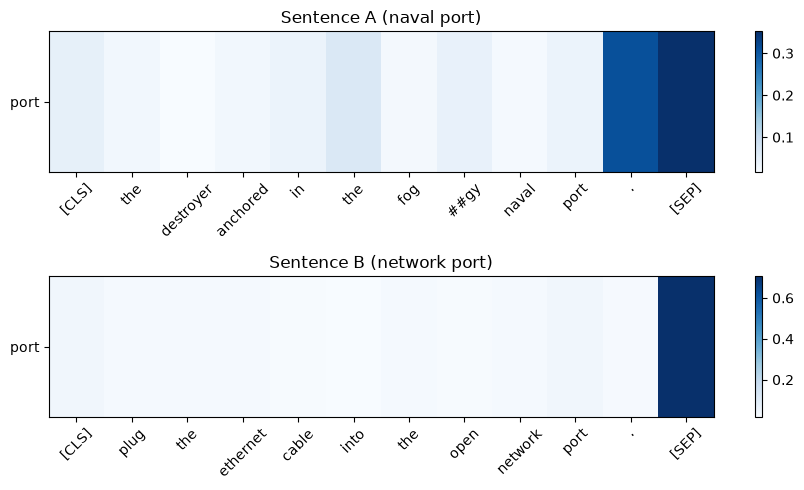

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5))

for ax, out, tokens, idx, title in [
    (axes[0], out_a, tokens_a, idx_port_a, "Sentence A (naval port)"),
    (axes[1], out_b, tokens_b, idx_port_b, "Sentence B (network port)"),
]:
    attn = out.attentions[-1][0].mean(dim=0)
    row = attn[idx].detach()
    im = ax.imshow(row[None, :], cmap="Blues", aspect="auto")
    ax.set_xticks(range(len(tokens)))
    ax.set_xticklabels(tokens, rotation=45)
    ax.set_yticks([0])
    ax.set_yticklabels(["port"])
    ax.set_title(title)
    fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()

This is interesting and odd behavior. My question is, why does no attention seem to be gained from the actual words, and it is all in the '.' and 'SEP' tokens? After some exploration and with the help of AI, I learned that this is due to what is called an "attention sink."  
  
This is when in the final transformer layer, most of the attention is sent to 'SEP' or '.' because their value vectors are low information (most sentences have them). By layer 6 in our example, "port" already has its context from earlier layers, so there is less need to pull in "naval" or "network" directly.  
  
However, this also makes me wonder, what if we plotted the same but at earlier layers?

Here are same style plots, but for layers 0, 1, and 2.

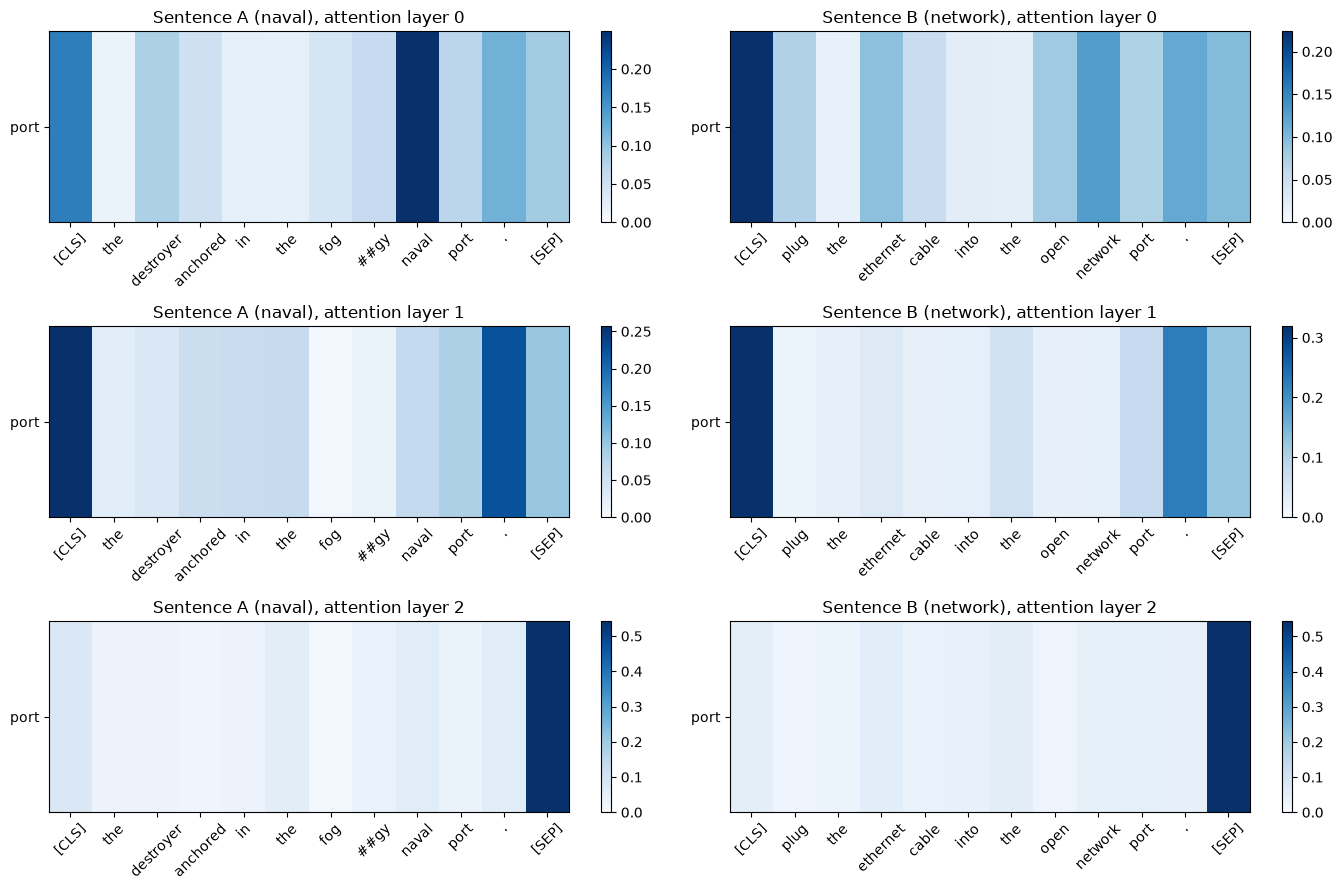

In [10]:
layers_to_plot = [0, 1, 2]

fig, axes = plt.subplots(len(layers_to_plot), 2, figsize=(14, 3 * len(layers_to_plot)))

for r, layer in enumerate(layers_to_plot):
    for c, (out, tokens, idx, name) in enumerate([
        (out_a, tokens_a, idx_port_a, "A (naval)"),
        (out_b, tokens_b, idx_port_b, "B (network)"),
    ]):
        attn = out.attentions[layer][0].mean(dim=0)
        row = attn[idx].detach()
        ax = axes[r, c]
        im = ax.imshow(row[None, :], cmap="Blues", aspect="auto", vmin=0, vmax=row.max().item())
        ax.set_xticks(range(len(tokens)))
        ax.set_xticklabels(tokens, rotation=45)
        ax.set_yticks([0])
        ax.set_yticklabels(["port"])
        ax.set_title(f"Sentence {name}, attention layer {layer}")
        fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()

As we can see from the above, both sentences now show where the attention truly is! At layer 0, context is being pulled heavily from "naval" in sentence A, and "network" in sentence B. By layers 1 and 2, the attention is already being passed to the 'CLS' token (a special DistilBERT token meaning classification), then to the '.' and 'SEP' tokens.